# Segmentación semántica de miotubos

Implementación del flujo semántico del reto *MyotubesAug_2026*, secciones 4.2 a 4.8. La entrada es una imagen gris de microscopía y el objetivo es la unión de las anotaciones en `masks_png/`. La salida es una máscara binaria a resolución original. Se conservan las 61 imágenes de validación de la semana 1.

Desde la raíz del repositorio, instala `python -m pip install -r requirements.txt torch opencv-python matplotlib`. Abre este notebook con el kernel del entorno y ejecuta todas las celdas. Se requiere el conjunto `vt/vt/`. El código se ejecutó en CPU y admite CUDA. Los resultados y paneles quedan en el notebook. Se guarda el manifiesto fijo en `resultados/particiones_miotubos.csv` y los checkpoints y cachés en `tmp/miotubos_revision/`.


In [1]:
from hashlib import sha256
from itertools import product
import json
import os
from pathlib import Path

import cv2
from IPython.display import display
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw
import torch
from torch import nn
from torch.nn import functional as F

from baseline import score_maps


ROOT = Path.cwd()
DATA = ROOT / "vt" / "vt"
RESULTS = ROOT / "resultados"
WORK = ROOT / "tmp" / "miotubos_revision"
CACHE = WORK / "cache"
CACHE.mkdir(parents=True, exist_ok=True)
MANIFEST = RESULTS / "particiones_miotubos.csv"
SEED = 2026
SCALE = 2
PATCH = 128
BATCH = 8
EPOCHS = 8
STEPS = 72
LEVELS = 4096
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
cv2.setNumThreads(1)

old_train = pd.read_csv(RESULTS / "train.csv")
old_val = pd.read_csv(RESULTS / "val.csv")
groups = sorted(set(old_train.group_id) - {"origen-no-confirmado"})
group_sizes = old_train.groupby("group_id").size().to_dict()
split_rng = np.random.default_rng(SEED)
target = round(0.15 * (len(old_train) + len(old_val)))
candidates = [split_rng.choice(groups, size=5, replace=False) for _ in range(500)]
test_groups = set(min(candidates, key=lambda candidate: abs(sum(group_sizes[g] for g in candidate) - target)))
is_test = old_train.group_id.isin(test_groups)
splits = {
    "Entrenamiento": old_train.loc[~is_test].reset_index(drop=True),
    "Validación": old_val,
    "Prueba": old_train.loc[is_test].reset_index(drop=True),
}
partition = pd.concat([frame.assign(particion=name) for name, frame in splits.items()], ignore_index=True)
assert partition.image_id.is_unique
assert len(partition) == len(old_train) + len(old_val)
assert partition.groupby("group_id").particion.nunique().max() == 1
split_by_image = partition.set_index("image").particion.to_dict()
for row in pd.read_csv(RESULTS / "similar_pairs.csv").itertuples(index=False):
    assert split_by_image[row.image_a] == split_by_image[row.image_b]
manifest = partition.to_csv(index=False, lineterminator="\n")
if MANIFEST.exists():
    assert MANIFEST.read_text(encoding="utf-8") == manifest, "El manifiesto fijo difiere de la partición regenerada"
else:
    MANIFEST.write_text(manifest, encoding="utf-8", newline="\n")

split_table = partition.groupby("particion", sort=False).agg(imagenes=("image_id", "size"), grupos=("group_id", "nunique"))
display(split_table)
print(f"Semilla {SEED} | PyTorch {torch.__version__} | OpenCV {cv2.__version__} | {DEVICE}")


def gray(path):
    image = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise ValueError(f"No se pudo leer {path}")
    return image


def image_features(image):
    size = (image.shape[1] // SCALE, image.shape[0] // SCALE)
    reduced = cv2.resize(image, size, interpolation=cv2.INTER_AREA)
    background = cv2.GaussianBlur(reduced, (0, 0), sigmaX=16 / SCALE)
    signed = np.clip(reduced.astype(np.int16) - background + 128, 0, 255).astype(np.uint8)
    return np.stack([reduced, signed])


def working_pair(record):
    paths = [DATA / record.image, DATA / record.mask]
    signature = repr([(str(p), p.stat().st_size, p.stat().st_mtime_ns) for p in paths])
    fingerprint = sha256(f"contrast16-nearest-v1:{SCALE}:{signature}".encode()).hexdigest()[:20]
    path = CACHE / f"{record.image_id}-{fingerprint}.npy"
    if not path.exists():
        image, mask = (gray(p) for p in paths)
        assert image.shape == mask.shape == (record.height, record.width)
        features = image_features(image)
        h, w = features.shape[1:]
        mask = cv2.resize((mask > 0).astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST_EXACT)
        np.save(path, np.concatenate([features, mask[None]]), allow_pickle=False)
    return np.load(path, mmap_mode="r", allow_pickle=False)


train_pairs = [working_pair(row) for row in splits["Entrenamiento"].itertuples(index=False)]
moments = []
for pair in train_pairs:
    channel_moments = []
    for channel in pair[:2]:
        mean, std = (float(value.item()) for value in cv2.meanStdDev(channel))
        channel_moments.append((mean, std**2 + mean**2))
    moments.append(channel_moments)
mean, second_moment = np.asarray(moments).mean(axis=0).T
std = np.sqrt(second_moment - mean**2)
mu = torch.tensor(mean, dtype=torch.float32, device=DEVICE)[None, :, None, None]
sigma = torch.tensor(std, dtype=torch.float32, device=DEVICE)[None, :, None, None]
print("Media de entrenamiento", mean.round(3), "| desviación", std.round(3))


def tensors(batch):
    x = torch.from_numpy(np.ascontiguousarray(batch[:, :2])).to(DEVICE, dtype=torch.float32)
    y = torch.from_numpy(np.ascontiguousarray(batch[:, 2:3])).to(DEVICE, dtype=torch.float32)
    return ((x - mu) / sigma).contiguous(memory_format=torch.channels_last), y


def positive_pixels(pairs):
    return {i: locations for i, pair in enumerate(pairs)
            if len(locations := np.flatnonzero(pair[2]).astype(np.int32))}


def crop(pairs, positive, rng, center_positive):
    index = int(rng.choice(list(positive))) if center_positive else int(rng.integers(len(pairs)))
    pair = pairs[index]
    h, w = pair.shape[1:]
    if center_positive:
        row, col = divmod(int(rng.choice(positive[index])), w)
        y = np.clip(row - rng.integers(PATCH // 4, 3 * PATCH // 4), 0, h - PATCH)
        x = np.clip(col - rng.integers(PATCH // 4, 3 * PATCH // 4), 0, w - PATCH)
    else:
        y, x = rng.integers(h - PATCH + 1), rng.integers(w - PATCH + 1)
    return pair[:, y:y+PATCH, x:x+PATCH]


train_pixels = positive_pixels(train_pairs)
monitor_ids = splits["Validación"].groupby("group_id", sort=True).head(3)
monitor_pairs = [working_pair(row) for row in monitor_ids.itertuples(index=False)]
monitor_pixels = positive_pixels(monitor_pairs)
monitor_rng = np.random.default_rng(SEED + 1)
monitor = np.stack([crop(monitor_pairs, monitor_pixels, monitor_rng, i % 3 == 0) for i in range(60)])


,imagenes,grupos
particion,,
Entrenamiento,199,21
Validación,61,5
Prueba,46,5


Semilla 2026 | PyTorch 2.9.1+cpu | OpenCV 4.12.0 | cpu
Media de entrenamiento [152.832 127.997] | desviación [29.713 24.189]


## Entradas, arquitecturas y desbalance

`PNG gris → escala 1:2 → gris + contraste firmado → normalización con estadísticas de entrenamiento → [B, 2, 128, 128] → logits [B, 1, 128, 128]`.

El contraste es la diferencia entre el gris reducido y su fondo suavizado con Gauss (σ=8 píxeles tras reducir). La máscara de ajuste se reduce por vecino más cercano y mantiene las clases discretas. En cada lote de ocho recortes, tres se centran cerca de un píxel positivo y cinco se toman de forma uniforme. Los mismos volteos y giros de 90° se aplican a entrada y máscara.

La CNN dilatada mantiene la resolución con cuatro convoluciones 3×3 de dilataciones 1, 2, 4 y 8. La U-Net codifica con 12, 24 y 32 canales, tiene dos max-pools, y decodifica concatenando las conexiones laterales. Se compara BCE con una mezcla de 0,5 BCE y 0,5 Dice suave en la U-Net. Las tres variantes tienen el mismo presupuesto de pasos y sus mejores épocas se guardan por F2 en un panel fijo de recortes de validación. Ese panel puede contener primer plano enriquecido y sus cifras sirven para el seguimiento de épocas.


In [2]:
def block(in_channels, out_channels, dilation=1):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, padding=dilation, dilation=dilation, bias=False),
        nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
    )


class DilatedCNN(nn.Sequential):
    def __init__(self):
        super().__init__(block(2, 12), block(12, 12, 2), block(12, 12, 4),
                         block(12, 12, 8), nn.Conv2d(12, 1, 1))


class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = nn.Sequential(block(2, 12), block(12, 12))
        self.enc2 = nn.Sequential(block(12, 24), block(24, 24))
        self.bridge = nn.Sequential(block(24, 32), block(32, 32))
        self.dec2 = nn.Sequential(block(56, 24), block(24, 24))
        self.dec1 = nn.Sequential(block(36, 12), block(12, 12))
        self.head = nn.Conv2d(12, 1, 1)

    def forward(self, inputs):
        e1 = self.enc1(inputs)
        e2 = self.enc2(F.max_pool2d(e1, 2))
        h = self.bridge(F.max_pool2d(e2, 2))
        h = self.dec2(torch.cat([F.interpolate(h, scale_factor=2, mode="nearest"), e2], dim=1))
        h = self.dec1(torch.cat([F.interpolate(h, scale_factor=2, mode="nearest"), e1], dim=1))
        return self.head(h)


CONFIGS = {
    "CNN dilatada · BCE+Dice": (DilatedCNN, True),
    "U-Net · BCE": (UNet, False),
    "U-Net · BCE+Dice": (UNet, True),
}


def objective(logit, target, with_dice):
    bce = F.binary_cross_entropy_with_logits(logit, target)
    if not with_dice:
        return bce
    probability = logit.sigmoid()
    dice = (2 * (probability * target).sum() + 1) / (probability.sum() + target.sum() + 1)
    return 0.5 * bce + 0.5 * (1 - dice)


def pixel_curve(counts):
    negative, positive = counts
    fp, tp = [np.r_[0, counts[::-1].cumsum()] for counts in (negative, positive)]
    fn = positive.sum() - tp
    precision = np.divide(tp, tp+fp, out=np.ones(len(tp)), where=(tp+fp)>0)
    recall = tp / positive.sum()
    dice = 2 * tp / (2 * tp + fp + fn)
    f2 = 5 * tp / (5 * tp + fp + 4 * fn)
    return {"tp": tp, "fp": fp, "fn": fn, "Precisión": precision, "Recall": recall, "Dice": dice, "F2": f2,
            "IoU": tp / (tp + fp + fn), "AP": float(np.sum(np.diff(recall) * precision[1:]))}


def pick_threshold(counts, criterion):
    return int(counts.shape[1] - pixel_curve(counts)[criterion].argmax())


def sample_training_batch(rng):
    batch = []
    for j in range(BATCH):
        patch = crop(train_pairs, train_pixels, rng, j < 3)
        patch = np.rot90(patch, int(rng.integers(4)), axes=(-2, -1))
        if rng.random() < 0.5:
            patch = patch[..., ::-1]
        batch.append(patch)
    return tensors(np.stack(batch))


@torch.inference_mode()
def monitor_scores(model):
    counts = np.zeros((2, LEVELS), dtype=np.int64)
    for i in range(0, len(monitor), BATCH):
        x, y = tensors(monitor[i:i+BATCH])
        scores = np.rint(model(x).sigmoid().cpu().numpy() * (LEVELS - 1)).astype(np.int64)
        bins = scores.ravel() + LEVELS * y.cpu().numpy().ravel().astype(np.int64)
        counts += np.bincount(bins, minlength=2 * LEVELS).reshape(2, LEVELS)
    curve = pixel_curve(counts)
    return curve["AP"], float(curve["F2"].max())


def train_run(name, model_class, with_dice, checkpoint):
    torch.manual_seed(SEED)
    rng = np.random.default_rng(SEED)
    model = model_class().to(DEVICE, memory_format=torch.channels_last)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.003, weight_decay=0.0001)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=0.0003)
    best_f2 = -1
    history = []
    for epoch in range(1, EPOCHS + 1):
        model.train()
        losses = []
        for _ in range(STEPS):
            x, y = sample_training_batch(rng)
            optimizer.zero_grad(set_to_none=True)
            loss = objective(model(x), y, with_dice)
            loss.backward()
            optimizer.step()
            losses.append(loss.detach())
        scheduler.step()
        model.eval()
        ap, f2 = monitor_scores(model)
        loss = float(torch.stack(losses).mean().cpu())
        history.append({"Modelo": name, "Época": epoch, "Pérdida": loss, "AP panel": ap, "F2 panel": f2})
        print(f"{name} | época {epoch} | pérdida {loss:.4f} | F2 panel {f2:.4f}", flush=True)
        if f2 > best_f2:
            best_f2 = f2
            torch.save(model.state_dict(), checkpoint)
    model.load_state_dict(torch.load(checkpoint, map_location=DEVICE, weights_only=True))
    return model.eval(), history


In [3]:
models = {}
histories = []
for index, (name, (model_class, with_dice)) in enumerate(CONFIGS.items(), start=1):
    models[name], history = train_run(name, model_class, with_dice, WORK / f"modelo_{index}.pt")
    histories.extend(history)
history_frame = pd.DataFrame(histories)
best_epochs = history_frame.loc[history_frame.groupby("Modelo", sort=False)["F2 panel"].idxmax()]
display(best_epochs.round(4).reset_index(drop=True))


CNN dilatada · BCE+Dice | época 1 | pérdida 0.6548 | F2 panel 0.4260
CNN dilatada · BCE+Dice | época 2 | pérdida 0.5227 | F2 panel 0.4492
CNN dilatada · BCE+Dice | época 3 | pérdida 0.4733 | F2 panel 0.4824
CNN dilatada · BCE+Dice | época 4 | pérdida 0.4482 | F2 panel 0.5006
CNN dilatada · BCE+Dice | época 5 | pérdida 0.4591 | F2 panel 0.4979
CNN dilatada · BCE+Dice | época 6 | pérdida 0.4144 | F2 panel 0.4993
CNN dilatada · BCE+Dice | época 7 | pérdida 0.4182 | F2 panel 0.5064
CNN dilatada · BCE+Dice | época 8 | pérdida 0.4304 | F2 panel 0.5025
U-Net · BCE | época 1 | pérdida 0.5547 | F2 panel 0.3561
U-Net · BCE | época 2 | pérdida 0.2706 | F2 panel 0.4361
U-Net · BCE | época 3 | pérdida 0.2058 | F2 panel 0.4882
U-Net · BCE | época 4 | pérdida 0.1925 | F2 panel 0.5114
U-Net · BCE | época 5 | pérdida 0.2116 | F2 panel 0.4664
U-Net · BCE | época 6 | pérdida 0.1730 | F2 panel 0.5132
U-Net · BCE | época 7 | pérdida 0.1860 | F2 panel 0.5200
U-Net · BCE | época 8 | pérdida 0.2002 | F2 panel

,Modelo,Época,Pérdida,AP panel,F2 panel
0,CNN dilatada · BCE+Dice,7,0.4182,0.2710,0.5064
1,U-Net · BCE,7,0.1860,0.2763,0.5200
2,U-Net · BCE+Dice,4,0.4395,0.3539,0.5317


## Validación y selección del umbral

Se cosen los logits en mosaicos sin solape en sus zonas centrales. Cada mosaico tiene un halo reflejado de 32 píxeles que se descarta al coser. Tras sigmoide, se interpola el mapa de scores a resolución original con interpolación bilineal. La decisión por umbral se toma en esa malla, sobre las máscaras PNG originales. Las redes conservan 4096 niveles de score en las curvas. La línea base conserva sus 256 niveles de contraste absoluto (Gauss de radio 2 y 28).

Se comparan dos umbrales definidos en las mismas 61 imágenes de validación. Maximizar Dice da el punto de referencia equilibrado. Maximizar F2 configura un punto sensible que pondera el recall más que la precisión. El modelo final es el de mayor F2 en validación completa. La AP se usa para comprobar si la separación por píxel mejora a lo largo de toda la curva. En caso de empate entre umbrales se toma el más alto.

La prueba reúne 46 imágenes de cinco grupos del antiguo entrenamiento. Se reservaron por semilla y tamaño de grupo antes de estos nuevos ajustes. La comparación con el contraste y el modelo final en esa prueba es retrospectiva porque esas imágenes formaban parte del conjunto accesible en las semanas previas. El UUID es un proxy de grupo. Las verificaciones usan grupos y duplicados conocidos.


In [4]:
@torch.inference_mode()
def network_map(model, planes):
    h, w = planes.shape[1:]
    core, halo = 384, 32
    pad_bottom, pad_right = -h % 4, -w % 4
    padded = np.pad(planes, ((0, 0), (halo, halo + pad_bottom), (halo, halo + pad_right)), mode="reflect")
    combined = np.empty((h + pad_bottom, w + pad_right), dtype=np.float32)
    for y, x in product(range(0, combined.shape[0], core), range(0, combined.shape[1], core)):
        end_y = min(y + core, combined.shape[0])
        end_x = min(x + core, combined.shape[1])
        tile = np.ascontiguousarray(padded[None, :, y:end_y+2*halo, x:end_x+2*halo])
        inputs = torch.from_numpy(tile).to(DEVICE, dtype=torch.float32)
        inputs = ((inputs - mu) / sigma).contiguous(memory_format=torch.channels_last)
        scores = model(inputs)[0, 0, halo:-halo, halo:-halo].sigmoid().cpu().numpy()
        combined[y:end_y, x:end_x] = scores
    return combined[:h, :w]


BASELINE = "Contraste absoluto"


def score_image(name, original, features):
    if name == BASELINE:
        return score_maps(Image.fromarray(original))["absoluto"]
    probability = network_map(models[name], features)
    native = cv2.resize(probability, original.shape[::-1], interpolation=cv2.INTER_LINEAR)
    native *= LEVELS - 1
    np.rint(native, out=native)
    return native.astype(np.uint16)


def score_counts(scores, mask, levels):
    background = cv2.bitwise_not(mask)
    return np.stack([
        cv2.calcHist([scores], [0], region, [levels], [0, levels]).ravel().astype(np.int64)
        for region in (background, mask)
    ])


def collect_counts(frame, names):
    totals = {name: np.zeros((2, 256 if name == BASELINE else LEVELS), dtype=np.int64) for name in names}
    image_counts = {name: {} for name in names}
    for record in frame.itertuples(index=False):
        image = gray(DATA / record.image)
        truth = (gray(DATA / record.mask) > 0).astype(np.uint8) * 255
        features = image_features(image)
        for name, total in totals.items():
            counts = score_counts(score_image(name, image, features), truth, total.shape[1])
            assert counts.sum() == record.width * record.height
            total += counts
            image_counts[name][record.image_id] = counts
    return totals, image_counts


def at_threshold(counts, threshold):
    curve = pixel_curve(counts)
    index = counts.shape[1] - threshold
    measures = {key: float(curve[key][index]) for key in ("IoU", "Dice", "Precisión", "Recall", "F2")}
    if curve["tp"][index] + curve["fp"][index] == 0:
        measures["Precisión"] = 0.0
    return measures | {"AP": curve["AP"]}


def result_rows(counts_by_model, criteria, part):
    rows = []
    for name, counts in counts_by_model.items():
        for criterion, threshold in criteria[name].items():
            shown = threshold if name == BASELINE else threshold / (LEVELS - 1)
            rows.append({"Partición": part, "Modelo": name, "Umbral por": criterion, "Umbral": shown,
                         **at_threshold(counts, threshold)})
    return rows


print(f"Validación completa · {len(splits['Validación'])} imágenes", flush=True)
validation_counts, _ = collect_counts(splits["Validación"], [BASELINE, *models])
published = json.loads((RESULTS / "metricas_validacion.json").read_text(encoding="utf-8"))
original_metrics = at_threshold(validation_counts[BASELINE], published["threshold"])
assert np.isclose(original_metrics["AP"], published["pr_auc"])
assert np.isclose(original_metrics["Recall"], published["recall"])
assert np.isclose(original_metrics["Dice"], published["dice"])

thresholds = {name: {criterion: pick_threshold(counts, criterion) for criterion in ("Dice", "F2")}
              for name, counts in validation_counts.items()}
validation_rows = result_rows(validation_counts, thresholds, "Validación")
selected = max(models, key=lambda name: at_threshold(validation_counts[name], thresholds[name]["F2"])["F2"])
print(f"Modelo fijado antes de evaluar la prueba · {selected}", flush=True)
display(pd.DataFrame(validation_rows).drop(columns="Partición").round(4))


Validación completa · 61 imágenes
Modelo fijado antes de evaluar la prueba · CNN dilatada · BCE+Dice


,Modelo,Umbral por,Umbral,IoU,Dice,Precisión,Recall,F2,AP
0,Contraste absoluto,Dice,15.0000,0.0558,0.1057,0.0665,0.2582,0.1638,0.0429
1,Contraste absoluto,F2,11.0000,0.0517,0.0984,0.0563,0.3881,0.1782,0.0429
2,CNN dilatada · BCE+Dice,Dice,0.3705,0.1190,0.2127,0.1504,0.3631,0.2831,0.1073
3,CNN dilatada · BCE+Dice,F2,0.1687,0.1087,0.1962,0.1225,0.4914,0.3067,0.1073
4,U-Net · BCE,Dice,0.2857,0.1147,0.2058,0.1447,0.3566,0.2758,0.1076
5,U-Net · BCE,F2,0.1661,0.1053,0.1906,0.1182,0.4917,0.3013,0.1076
6,U-Net · BCE+Dice,Dice,0.2596,0.1001,0.1819,0.1294,0.3062,0.2405,0.0954
7,U-Net · BCE+Dice,F2,0.1021,0.0897,0.1646,0.1004,0.4562,0.2670,0.0954


## Evaluación en prueba y revisión visual

En prueba se evalúan el contraste y el modelo seleccionado con los dos umbrales ya fijados en validación. IoU, Dice, precisión y recall se acumulan sobre todos los píxeles. La AP y F2 ayudan a interpretar la separación y la sensibilidad. Los ejemplos visuales se eligen con una regla reproducible para mostrar un caso típico, una omisión y un falso positivo.


Prueba con umbrales fijos · 46 imágenes


,Modelo,Umbral por,Umbral,IoU,Dice,Precisión,Recall,F2,AP
0,Contraste absoluto,Dice,15.0000,0.0287,0.0558,0.0309,0.2875,0.1081,0.0211
1,Contraste absoluto,F2,11.0000,0.0256,0.0499,0.0265,0.4340,0.1064,0.0211
2,CNN dilatada · BCE+Dice,Dice,0.3705,0.0804,0.1489,0.0895,0.4437,0.2476,0.0718
3,CNN dilatada · BCE+Dice,F2,0.1687,0.0694,0.1298,0.0726,0.6109,0.2461,0.0718


Recall máximo en la curva de validación con precisión ≥ 15.39%: 34.18%
Caso mediano · imagen 62


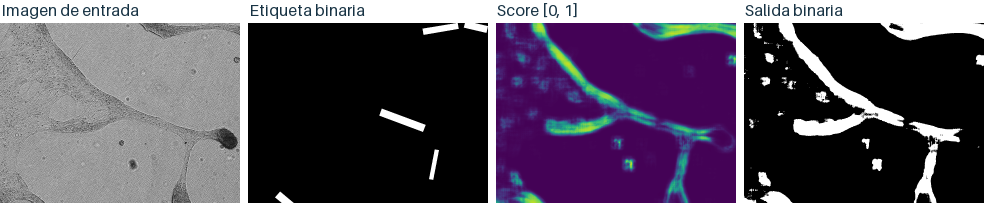

Mayor omisión · imagen 69


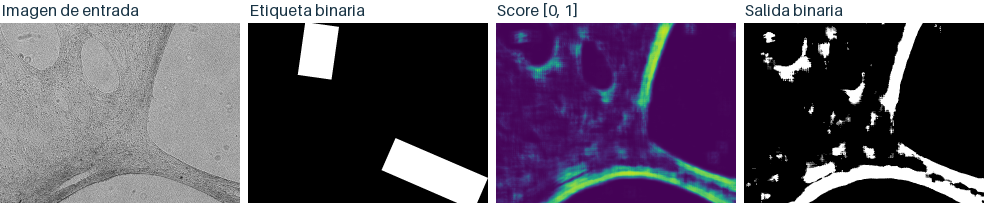

Falsos positivos · imagen 256


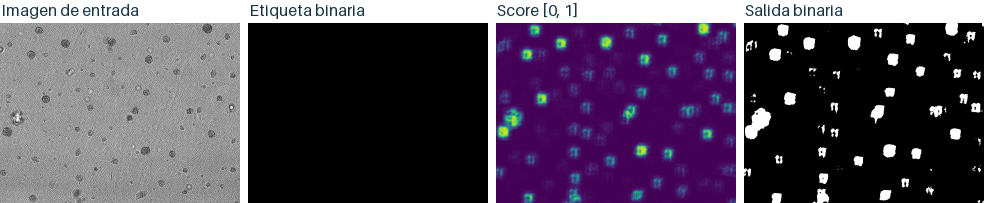

In [5]:
from PIL import ImageFont


print(f"Prueba con umbrales fijos · {len(splits['Prueba'])} imágenes", flush=True)
test_counts, test_image_counts = collect_counts(splits["Prueba"], [BASELINE, selected])
test_rows = result_rows(test_counts, thresholds, "Prueba")
display(pd.DataFrame(test_rows).drop(columns="Partición").round(4))

previous_precision = 0.153915  # CNN de la entrega anterior, elegida en una calibración distinta.
curve = pixel_curve(validation_counts[selected])
eligible = (curve["Precisión"] >= previous_precision) & (curve["tp"] + curve["fp"] > 0)
recall_at_previous_precision = float(curve["Recall"][eligible].max()) if eligible.any() else None
print(f"Recall máximo en la curva de validación con precisión ≥ {previous_precision:.2%}: "
      f"{recall_at_previous_precision:.2%}" if eligible.any() else "Sin umbral comparable por precisión")


def per_image_metrics(histograms, threshold):
    rows = []
    for image_id, hist in histograms.items():
        fp, tp = hist[:, threshold:].sum(axis=1)
        fn = hist[1, :threshold].sum()
        rows.append({"image_id": image_id, "TP": int(tp), "FP": int(fp), "FN": int(fn), "Positivos": int(tp+fn),
                     "Dice": float(2*tp/(2*tp+fp+fn)) if 2*tp+fp+fn else None,
                     "Recall": float(tp/(tp+fn)) if tp+fn else None})
    return pd.DataFrame(rows)


image_metrics = per_image_metrics(test_image_counts[selected], thresholds[selected]["F2"])
annotated = image_metrics.loc[image_metrics.Positivos > 0].sort_values(["Dice", "image_id"])
typical = annotated.iloc[len(annotated) // 2]
omitted = annotated.loc[annotated.image_id != typical.image_id].sort_values(["FN", "image_id"], ascending=[False, True]).iloc[0]
other = image_metrics.loc[~image_metrics.image_id.isin([typical.image_id, omitted.image_id])]
empty = other.loc[other.Positivos == 0]
false_alarm = (empty if len(empty) else other).sort_values(["FP", "image_id"], ascending=[False, True]).iloc[0]
cases = [("Caso mediano", typical, "TP"), ("Mayor omisión", omitted, "FN"), ("Falsos positivos", false_alarm, "FP")]


def crop_region(target, width=960, height=720):
    integral = cv2.integral(target.astype(np.uint8))
    sums = integral[height:, width:] + integral[:-height, :-width] - integral[height:, :-width] - integral[:-height, width:]
    y, x = np.unravel_index(sums.argmax(), sums.shape)
    return np.s_[y:y+height, x:x+width]


def panel_image(record, focus, threshold):
    image = gray(DATA / record["image"])
    truth = gray(DATA / record["mask"]) > 0
    scores = score_image(selected, image, image_features(image))
    predicted = scores >= threshold
    category = {"TP": truth & predicted, "FN": truth & ~predicted, "FP": ~truth & predicted}[focus]
    area = crop_region(category if category.any() else truth | predicted)
    patch_image = image[area]
    shape = (240, 180)
    rgb_score = cv2.applyColorMap(np.rint(scores[area] / (LEVELS - 1) * 255).astype(np.uint8), cv2.COLORMAP_VIRIDIS)
    tiles = [
        Image.fromarray(patch_image).convert("RGB").resize(shape, Image.Resampling.BOX),
        Image.fromarray(truth[area].astype(np.uint8) * 255).convert("RGB").resize(shape, Image.Resampling.BOX),
        Image.fromarray(cv2.cvtColor(rgb_score, cv2.COLOR_BGR2RGB)).resize(shape, Image.Resampling.BOX),
        Image.fromarray(predicted[area].astype(np.uint8) * 255).convert("RGB").resize(shape, Image.Resampling.BOX),
    ]
    preview = Image.new("RGB", (4 * shape[0] + 3 * 8, shape[1] + 23), "white")
    draw = ImageDraw.Draw(preview)
    font = ImageFont.load_default(size=16)
    for i, (tile, title) in enumerate(zip(tiles, ("Imagen de entrada", "Etiqueta binaria", "Score [0, 1]", "Salida binaria"))):
        x = i * (shape[0] + 8)
        draw.text((x+1, 0), title, fill="#183344", font=font)
        preview.paste(tile, (x, 23))
    return preview


examples = []
for i, (title, row, focus) in enumerate(cases, start=1):
    image_id = int(row.image_id)
    record = splits["Prueba"].loc[splits["Prueba"].image_id == image_id].iloc[0]
    panel = panel_image(record, focus, thresholds[selected]["F2"])
    path = WORK / f"ejemplo_{i}.png"
    panel.save(path)
    examples.append({"Caso": title, "ID": image_id, "Dice": None if pd.isna(row.Dice) else float(row.Dice),
                     "Recall": None if pd.isna(row.Recall) else float(row.Recall), "FP": int(row.FP),
                     "FN": int(row.FN), "Archivo": path.name})
    print(f"{title} · imagen {image_id}")
    display(panel)


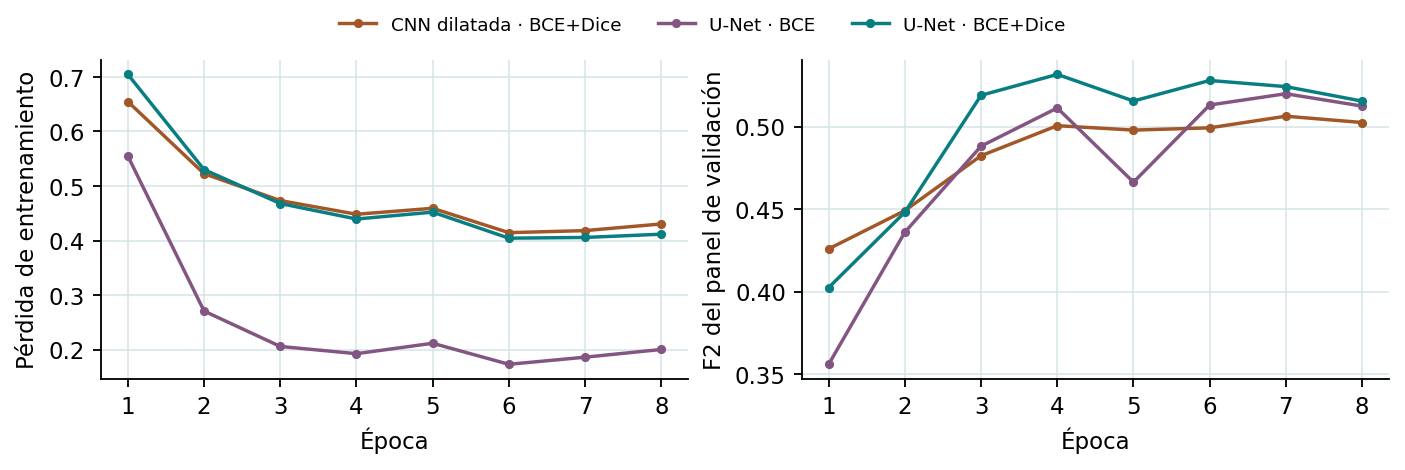

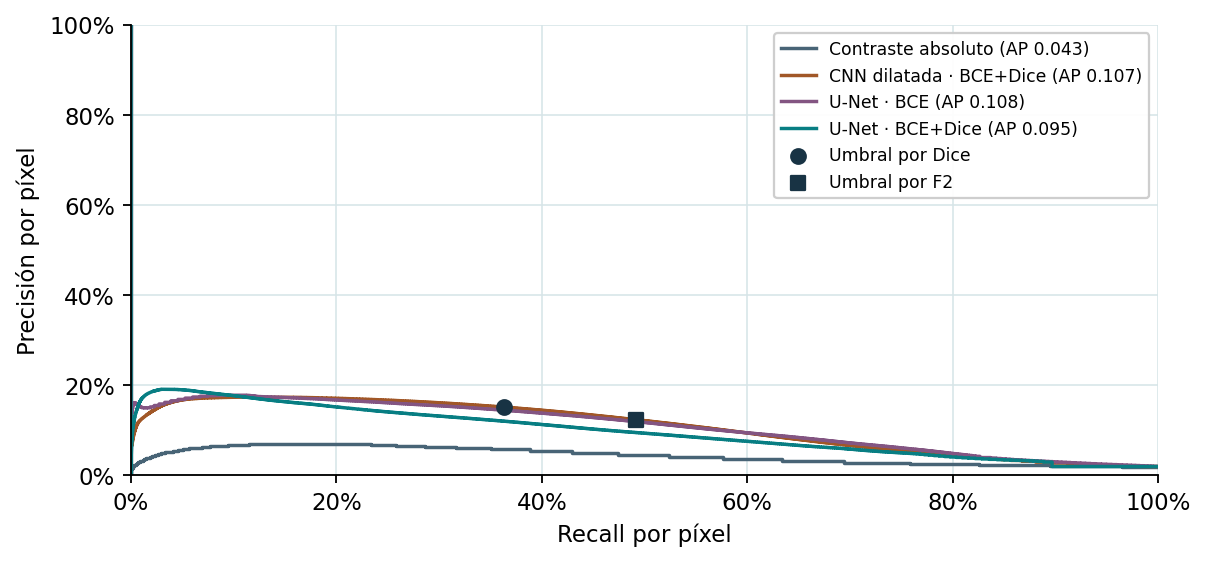

In [6]:
from matplotlib.figure import Figure
from matplotlib.ticker import PercentFormatter


palette = ["#486476", "#a15727", "#835582", "#087e83"]


def style_axis(axis):
    axis.spines[["top", "right"]].set_visible(False)
    axis.grid(color="#d7e5e8", linewidth=0.7)
    axis.set_axisbelow(True)


def show_figure(fig, name):
    path = WORK / f"{name}.png"
    fig.savefig(path, dpi=165, bbox_inches="tight", facecolor="white")
    with Image.open(path) as graphic:
        display(graphic.copy())


fig = Figure(figsize=(8.4, 2.75), layout="constrained")
axes = fig.subplots(1, 2)
for color, (name, series) in zip(palette[1:], history_frame.groupby("Modelo", sort=False)):
    axes[0].plot(series["Época"], series["Pérdida"], marker="o", ms=3, color=color, label=name)
    axes[1].plot(series["Época"], series["F2 panel"], marker="o", ms=3, color=color)
for axis, label in zip(axes, ("Pérdida de entrenamiento", "F2 del panel de validación")):
    style_axis(axis)
    axis.set(xlabel="Época", ylabel=label, xticks=range(1, EPOCHS+1))
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside upper center", ncols=3, fontsize=8, frameon=False)
show_figure(fig, "curvas_ajuste")

fig = Figure(figsize=(7.2, 3.3), layout="constrained")
axis = fig.subplots()
for name, color in zip(validation_counts, palette):
    series = pixel_curve(validation_counts[name])
    axis.step(series["Recall"], series["Precisión"], where="pre", label=f"{name} (AP {series['AP']:.3f})", color=color)
for criterion, form in [("Dice", "o"), ("F2", "s")]:
    values = at_threshold(validation_counts[selected], thresholds[selected][criterion])
    axis.scatter(values["Recall"], values["Precisión"], s=40, marker=form, color="#183344", label=f"Umbral por {criterion}", zorder=5)
axis.set(xlabel="Recall por píxel", ylabel="Precisión por píxel", xlim=(0, 1), ylim=(0, 1))
axis.xaxis.set_major_formatter(PercentFormatter(1))
axis.yaxis.set_major_formatter(PercentFormatter(1))
style_axis(axis)
axis.legend(loc="upper right", fontsize=7.5, framealpha=0.95)
show_figure(fig, "precision_recall")

prevalence = {"Validación": float(validation_counts[BASELINE][1].sum() / validation_counts[BASELINE].sum()),
              "Prueba": float(test_counts[BASELINE][1].sum() / test_counts[BASELINE].sum())}
summary = {
    "particiones": split_table.to_dict("index"), "validacion": validation_rows, "prueba": test_rows,
    "modelo": selected, "prevalencia": prevalence, "ejemplos": examples, "epocas": history_frame.to_dict("records"),
    "recall_a_precision_anterior": recall_at_previous_precision,
    "parametros": {name: sum(p.numel() for p in model.parameters()) for name, model in models.items()},
    "semana1": original_metrics,
}
_ = (WORK / "resumen.json").write_text(json.dumps(summary, ensure_ascii=False, allow_nan=False, indent=2) + "\n", encoding="utf-8")


## Lectura de las métricas

Compara primero los dos umbrales del mismo modelo. Sus mapas de score son idénticos. Las diferencias de recall, precisión y Dice aíslan el efecto de la decisión binaria. La AP de validación y el recall a la precisión de la CNN anterior permiten revisar la capacidad de separar miotubo y fondo. En prueba, las cifras corresponden exclusivamente a los umbrales de validación.

En la ejecución registrada, pasar de Dice a F2 en la CNN llevó el recall de 36,3 % a 49,1 % en validación y de 44,4 % a 61,1 % en prueba. La precisión de prueba bajó de 8,9 % a 7,3 %. La AP de validación quedó cerca de la CNN anterior (0,1073 frente a 0,1065) y superó la referencia clásica (0,0429). En la U-Net, añadir Dice redujo F2 de 0,301 a 0,267 en validación completa.

La segmentación binaria puede fusionar miotubos vecinos. Si se necesita contarlos o separarlos, las anotaciones COCO permiten definir un experimento de segmentación por instancia con una evaluación propia.

En esta ejecución, la imagen 62 muestra predicciones que se extienden más allá de los tramos anotados. En la 69, el modelo responde al contorno curvo y omite parte del tramo ancho de la etiqueta. En la 256, la máscara está vacía y el modelo responde a varias estructuras redondas. El patrón es consistente con sensibilidad al contraste local y con una separación incompleta entre miotubos y otros bordes.
